In [ ]:
import torch

# Automatically select GPU if available, else CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using device: {device}")


Using device: cuda


**FOR** **TESTING**

In [ ]:


import torch
import torch.nn as nn
from torchvision import models

class LightSpatialAttention(nn.Module):
    def __init__(self, in_channels):
        super(LightSpatialAttention, self).__init__()
        self.conv_d2 = nn.Conv2d(in_channels, 1, kernel_size=3, padding=2, dilation=2)
        self.conv_d3 = nn.Conv2d(in_channels, 1, kernel_size=3, padding=3, dilation=3)
        self.conv_d4 = nn.Conv2d(in_channels, 1, kernel_size=3, padding=4, dilation=4)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        attn = self.conv_d2(x) + self.conv_d3(x) + self.conv_d4(x)
        attn = self.sigmoid(attn)
        return x * attn

class MultiTaskFundusNet(nn.Module):
    def __init__(self, backbone_name="efficientnet_b0", pretrained=True):
        super(MultiTaskFundusNet, self).__init__()
        self.backbone = getattr(models, backbone_name)(weights='IMAGENET1K_V1' if pretrained else None)
        self.features = self.backbone.features
        out_channels = self.backbone.classifier[1].in_features
        self.attn = LightSpatialAttention(out_channels)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc_gender = nn.Linear(out_channels, 1)
        self.fc_age = nn.Linear(out_channels, 1)
        self.fc_diabetes = nn.Linear(out_channels, 1)

    def forward(self, x):
        x = self.features(x)
        x = self.attn(x)
        x = self.pool(x).flatten(1)
        gender = torch.sigmoid(self.fc_gender(x))
        age = self.fc_age(x)
        diabetes = torch.sigmoid(self.fc_diabetes(x))
        return gender, age, diabetes


# Run on CPU with pretrained weights
device = torch.device("cuda")
model = MultiTaskFundusNet("efficientnet_b0", pretrained=True).to(device)
model.eval()

dummy_input = torch.randn(2, 3, 128, 128).to(device)
with torch.no_grad():
    gender, age, diabetes = model(dummy_input)

print("Gender:", gender)
print("Age:", age)
print("Diabetes:", diabetes)



Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 156MB/s]


Gender: tensor([[0.5264],
        [0.5241]], device='cuda:0')
Age: tensor([[0.0667],
        [0.0611]], device='cuda:0')
Diabetes: tensor([[0.5009],
        [0.5006]], device='cuda:0')


In [ ]:
print(next(model.parameters()).device)


cuda:0


**ACTUAL** **CODE**

In [1]:
from google.colab import drive
drive.mount('/content/drive')
csv_path = "/content/drive/My Drive/ODIR-5K/full_df.csv"
image_dir = "/content/drive/My Drive/ODIR-5K/Training Images"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import pandas as pd
from tqdm import tqdm
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, mean_squared_error
import numpy as np

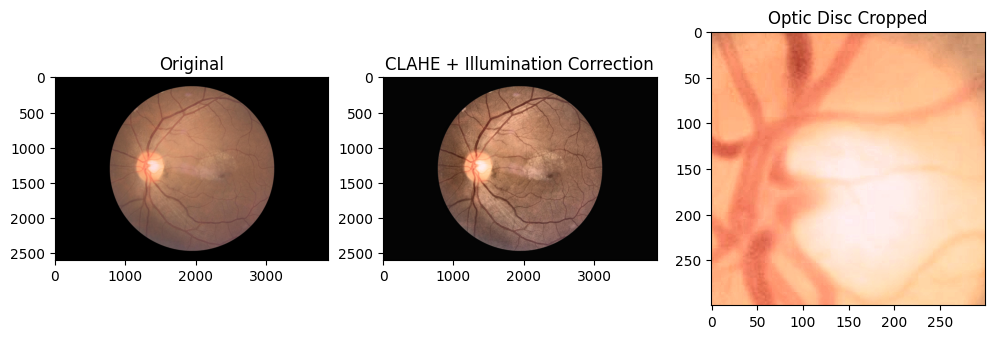

In [3]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# ------------------------------------------
# CLAHE + Gaussian Illumination Correction
# ------------------------------------------
def normalize_illumination(img):
    # Convert to LAB color space
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)

    # Apply CLAHE on L-channel
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    cl = clahe.apply(l)

    # Merge and convert back to RGB
    merged = cv2.merge((cl, a, b))
    img_clahe = cv2.cvtColor(merged, cv2.COLOR_LAB2RGB)

    # Gaussian blur to reduce uneven illumination
    img_blur = cv2.GaussianBlur(img_clahe, (9,9), 0)
    corrected = cv2.addWeighted(img_clahe, 1.5, img_blur, -0.5, 0)
    return corrected

# ------------------------------------------
# Optic Disc Cropping (Brightest Region)
# ------------------------------------------
def crop_optic_disc(img, crop_size=300):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    gray_blur = cv2.GaussianBlur(gray, (15,15), 0)

    # Find brightest spot (optic disc approx)
    minVal, maxVal, minLoc, maxLoc = cv2.minMaxLoc(gray_blur)

    x, y = maxLoc
    h, w, _ = img.shape
    x1 = max(x - crop_size//2, 0)
    y1 = max(y - crop_size//2, 0)
    x2 = min(x + crop_size//2, w)
    y2 = min(y + crop_size//2, h)

    cropped = img[y1:y2, x1:x2]
    return cropped

# ------------------------------------------
# Example
# ------------------------------------------
img_path = "/content/drive/MyDrive/ODIR-5K/Training Images/100_left.jpg"
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

img_norm = normalize_illumination(img)
img_crop = crop_optic_disc(img_norm)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(img)
plt.title("Original")

plt.subplot(1,3,2)
plt.imshow(img_norm)
plt.title("CLAHE + Illumination Correction")

plt.subplot(1,3,3)
plt.imshow(img_crop)
plt.title("Optic Disc Cropped")
plt.show()


In [4]:
from torch.utils.data import Dataset
from PIL import Image
import torch
import os # Import os for path joining

class FundusDataset(Dataset):
    def __init__(self, csv_path, image_dir, transform=None):
        self.data = pd.read_csv(csv_path)
        self.image_dir = image_dir # Store image_dir
        self.transform = transform

        # Clean gender
        self.data['Patient Sex'] = self.data['Patient Sex'].str.upper().str.strip()
        self.data['Patient Sex'] = self.data['Patient Sex'].map({'MALE': 1, 'FEMALE': 0})
        self.data['Patient Sex'] = self.data['Patient Sex'].fillna(0)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        # Extract only the base filename from the 'filepath' column
        img_filename = os.path.basename(row['filepath'])
        img_path = os.path.join(self.image_dir, img_filename) # Construct full path
        image = Image.open(img_path).convert('RGB')

        # Labels
        gender = torch.tensor(float(row['Patient Sex']))
        age = torch.tensor(float(row['Patient Age']) / 100.0)  # normalize to 0–1
        diabetes = torch.tensor(float(row['D']))  # 1 if diabetic, else 0

        if self.transform:
            image = self.transform(image)

        return image, gender, age, diabetes

In [ ]:
from torch.utils.data import Dataset
from PIL import Image
import torch
import os # Import os for path joining

class FundusDataset(Dataset):
    def __init__(self, csv_path, image_dir, transform=None):
        self.data = pd.read_csv(csv_path)
        self.image_dir = image_dir # Store image_dir
        self.transform = transform

        # Clean gender
        self.data['Patient Sex'] = self.data['Patient Sex'].str.upper().str.strip()
        self.data['Patient Sex'] = self.data['Patient Sex'].map({'MALE': 1, 'FEMALE': 0})
        self.data['Patient Sex'] = self.data['Patient Sex'].fillna(0)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        # Extract only the base filename from the 'filepath' column
        img_filename = os.path.basename(row['filepath'])
        img_path = os.path.join(self.image_dir, img_filename) # Construct full path
        image = Image.open(img_path).convert('RGB')

        # Labels
        gender = torch.tensor(float(row['Patient Sex']))
        age = torch.tensor(float(row['Patient Age']) / 100.0)  # normalize to 0–1
        diabetes = torch.tensor(float(row['D']))  # 1 if diabetic, else 0

        if self.transform:
            image = self.transform(image)

        return image, gender, age, diabetes

In [ ]:
#age = torch.tensor(row['Age'], dtype=torch.float32)

In [5]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = FundusDataset(csv_path,
                              image_dir,
                              transform=transform)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=2)

In [6]:
class LightSpatialAttention(nn.Module):
    def __init__(self, in_channels):
        super(LightSpatialAttention, self).__init__()
        self.conv_d2 = nn.Conv2d(in_channels, 1, kernel_size=3, padding=2, dilation=2)
        self.conv_d3 = nn.Conv2d(in_channels, 1, kernel_size=3, padding=3, dilation=3)
        self.conv_d4 = nn.Conv2d(in_channels, 1, kernel_size=3, padding=4, dilation=4)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        attn = self.conv_d2(x) + self.conv_d3(x) + self.conv_d4(x)
        attn = self.sigmoid(attn)
        return x * attn

class MultiTaskFundusNet(nn.Module):
    def __init__(self, backbone_name="efficientnet_b0", pretrained=True):
        super(MultiTaskFundusNet, self).__init__()
        self.backbone = getattr(models, backbone_name)(weights='IMAGENET1K_V1' if pretrained else None)
        self.features = self.backbone.features
        out_channels = self.backbone.classifier[1].in_features
        self.attn = LightSpatialAttention(out_channels)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc_gender = nn.Linear(out_channels, 1)
        self.fc_age = nn.Linear(out_channels, 1)
        self.fc_diabetes = nn.Linear(out_channels, 1)

    def forward(self, x):
        x = self.features(x)
        x = self.attn(x)
        x = self.pool(x).flatten(1)
        gender = torch.sigmoid(self.fc_gender(x))
        age = self.fc_age(x)
        diabetes = torch.sigmoid(self.fc_diabetes(x))
        return gender, age, diabetes


In [ ]:
class LightSpatialAttention(nn.Module):
    def __init__(self, in_channels):
        super(LightSpatialAttention, self).__init__()
        self.conv_d2 = nn.Conv2d(in_channels, 1, kernel_size=3, padding=2, dilation=2)
        self.conv_d3 = nn.Conv2d(in_channels, 1, kernel_size=3, padding=3, dilation=3)
        self.conv_d4 = nn.Conv2d(in_channels, 1, kernel_size=3, padding=4, dilation=4)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        attn = self.conv_d2(x) + self.conv_d3(x) + self.conv_d4(x)
        attn = self.sigmoid(attn)
        return x * attn

class MultiTaskFundusNet(nn.Module):
    def __init__(self, backbone_name="efficientnet_b0", pretrained=True):
        super(MultiTaskFundusNet, self).__init__()
        self.backbone = getattr(models, backbone_name)(weights='IMAGENET1K_V1' if pretrained else None)
        self.features = self.backbone.features
        out_channels = self.backbone.classifier[1].in_features
        self.attn = LightSpatialAttention(out_channels)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc_gender = nn.Linear(out_channels, 1)
        self.fc_age = nn.Linear(out_channels, 1)
        self.fc_diabetes = nn.Linear(out_channels, 1)

    def forward(self, x):
        x = self.features(x)
        x = self.attn(x)
        x = self.pool(x).flatten(1)
        gender = torch.sigmoid(self.fc_gender(x))
        age = self.fc_age(x)
        diabetes = torch.sigmoid(self.fc_diabetes(x))
        return gender, age, diabetes


In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MultiTaskFundusNet("efficientnet_b0", pretrained=True).to(device)

The training loop in cell `_97W7s3_gLy1` iterates through epochs and batches of data to train the `MultiTaskFundusNet` model.

Here's a breakdown:

*   **Model and Optimizer Initialization**: The `MultiTaskFundusNet` is instantiated, moved to the GPU (`.to(device)`), and an `Adam` optimizer is set up to update its parameters. Loss functions (`BCELoss` for binary classification tasks like gender and diabetes, and `MSELoss` for age regression) are also defined.
*   **Epoch Loop**: The code iterates for a specified number of `num_epochs`.
*   **DataLoader Iteration**: Inside each epoch, it iterates through the `train_loader` to get batches of images and their corresponding ground truth labels (gender, age, diabetes).
*   **Forward Pass**: For each batch, the images are moved to the device (GPU), and then passed through the `model` to get predictions for gender, age, and diabetes.
*   **Loss Calculation**: The individual losses for gender (`loss_gender`), age (`loss_age`), and diabetes (`loss_diabetes`) are calculated using their respective loss functions. These individual losses are then combined into a `total_loss`.
*   **Backward Pass and Optimization**: `total_loss.backward()` computes the gradients of the loss with respect to the model parameters, and `optimizer.step()` updates the model's weights. `optimizer.zero_grad()` clears the gradients for the next iteration.
*   **Progress Tracking**: `tqdm` is used to display a progress bar, and the average loss for each epoch is printed.

In [10]:
model.eval()
g_preds, d_preds, g_trues, d_trues, ages_pred, ages_true = [], [], [], [], [], []

with torch.no_grad():
    for images, g_true, a_true, d_true in tqdm(train_loader):
        images = images.to(device)
        g_pred, a_pred, d_pred = model(images)
        g_preds.extend(g_pred.cpu().numpy().flatten())
        d_preds.extend(d_pred.cpu().numpy().flatten())
        g_trues.extend(g_true.numpy().flatten())
        d_trues.extend(d_true.numpy().flatten())
        ages_pred.extend(a_pred.cpu().numpy().flatten())
        ages_true.extend(a_true.numpy().flatten())

g_preds_bin = [1 if p>0.5 else 0 for p in g_preds]
d_preds_bin = [1 if p>0.5 else 0 for p in d_preds]

print("Gender Accuracy:", accuracy_score(g_trues, g_preds_bin))
print("Gender F1:", f1_score(g_trues, g_preds_bin))
print("Diabetes AUC:", roc_auc_score(d_trues, d_preds))
print("Age RMSE:", np.sqrt(mean_squared_error(ages_true, ages_pred)))

  3%|▎         | 21/799 [00:17<10:46,  1.20it/s]


KeyboardInterrupt: 

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# Threshold at 0.5
d_preds_bin = [1 if p > 0.5 else 0 for p in d_preds]

diabetes_acc = accuracy_score(d_trues, d_preds_bin)
diabetes_f1 = f1_score(d_trues, d_preds_bin)

print(f"Diabetes Accuracy: {diabetes_acc:.4f}")
print(f"Diabetes F1: {diabetes_f1:.4f}")


Diabetes Accuracy: 0.8370
Diabetes F1: 0.6971


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error

# Denormalize back to years
ages_pred_real = np.array(ages_pred)*100
ages_true_real = np.array(ages_true)*100

age_mae = mean_absolute_error(ages_true_real, ages_pred_real)
print(f"Age MAE: {age_mae:.2f} years")


Age MAE: 9.83 years


In [ ]:
import scipy.stats as stats
r, _ = stats.pearsonr(ages_true_real, ages_pred_real)
print(f"Age–Prediction Correlation: {r:.3f}")


Age–Prediction Correlation: 0.422


In [ ]:
torch.save(model.state_dict(), "multitask_fundus_model.pth")
print(" Model saved successfully!")


✅ Model saved successfully!


In [ ]:
print("Pred Age Mean:", np.mean(ages_pred))
print("Pred Age Range:", np.min(ages_pred), "-", np.max(ages_pred))


Pred Age Mean: 0.60938126
Pred Age Range: 0.20751224 - 1.1761482


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:1866: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


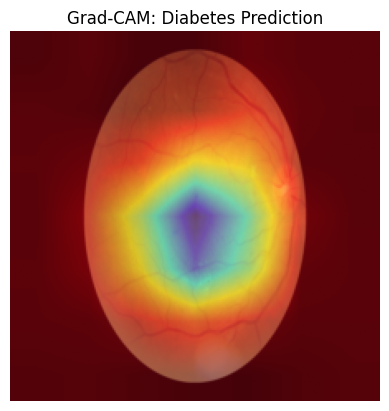

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 10. GRAD-CAM (EXPLAINABLE AI)
# ============================================================

class GradCAM:
    """
    Grad-CAM for diabetes prediction head
    """
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, inp, out):
            self.activations = out.detach()

        def backward_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0].detach()

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_backward_hook(backward_hook)

    def generate(self, input_tensor):
        self.model.zero_grad()
        _, _, d_pred = self.model(input_tensor)
        d_pred.backward(torch.ones_like(d_pred))

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1)
        cam = F.relu(cam)

        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        return cam


# ============================================================
# 11. GRAD-CAM VISUALIZATION
# ============================================================

target_layer = model.features[-1]
grad_cam = GradCAM(model, target_layer)

images, _, _, _ = next(iter(train_loader))
input_img = images[0].unsqueeze(0).to(device)

cam = grad_cam.generate(input_img)

def overlay_cam(img_tensor, cam):
    img = img_tensor.permute(1, 2, 0).cpu().numpy()
    img = (img - img.min()) / (img.max() - img.min())
    cam = cv2.resize(cam, (img.shape[1], img.shape[0]))
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = heatmap / 255
    return (heatmap + img) / 2

overlay = overlay_cam(input_img[0], cam)
plt.imshow(overlay)
plt.axis('off')
plt.title("Grad-CAM: Diabetes Prediction")
plt.show()


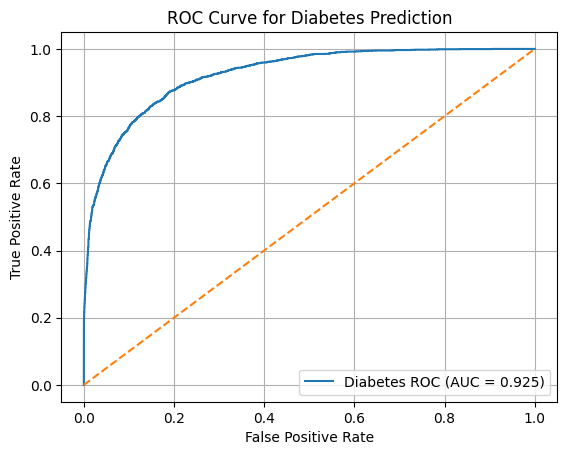

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(d_trues, d_preds)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure()
plt.plot(fpr, tpr, label=f"Diabetes ROC (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Diabetes Prediction")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


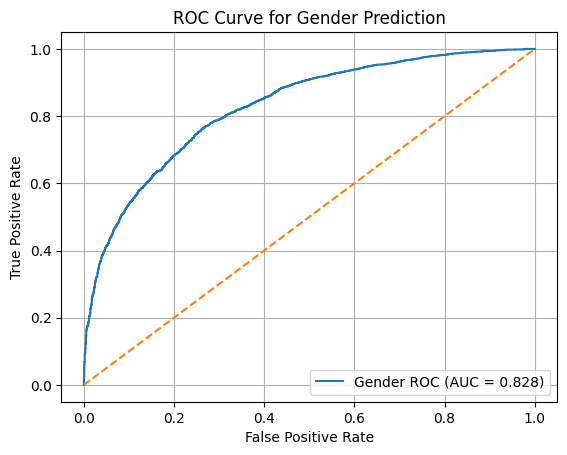

In [ ]:
# ROC for Gender
fpr_g, tpr_g, _ = roc_curve(g_trues, g_preds)
roc_auc_g = auc(fpr_g, tpr_g)

plt.figure()
plt.plot(fpr_g, tpr_g, label=f"Gender ROC (AUC = {roc_auc_g:.3f})")
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Gender Prediction")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


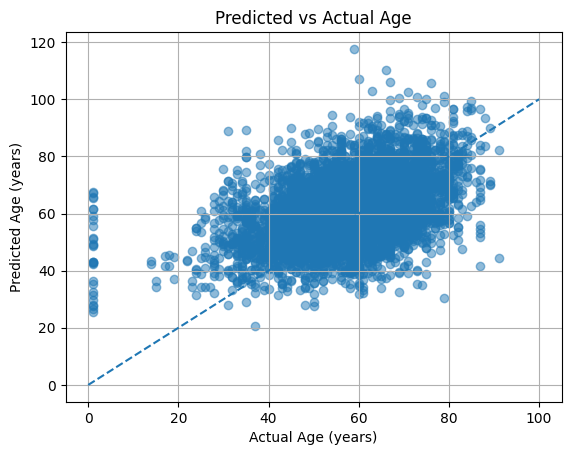

In [ ]:
import matplotlib.pyplot as plt

plt.figure()
plt.scatter(ages_true_real, ages_pred_real, alpha=0.5)
plt.plot([0, 100], [0, 100], linestyle='--')  # Ideal prediction line
plt.xlabel("Actual Age (years)")
plt.ylabel("Predicted Age (years)")
plt.title("Predicted vs Actual Age")
plt.grid(True)
plt.show()
